# 10 · The linear-quadratic regulator

Pole placement asks where the poles should go and leaves the answer to taste; the linear-quadratic regulator
asks what the control should cost. Minimising ∫(xᵀQx + uᵀRu) dt over all state feedbacks gives u = −Kx with
K = R⁻¹BᵀP and P the stabilising solution of the algebraic Riccati equation - a controller that trades state
error against control effort by weights an engineer can argue about, that works for any number of inputs, and
that comes with guaranteed margins. This notebook solves the Riccati equation, verifies optimality, sweeps the
weights, adds integral action, and measures the margins on the cart-pendulum and the DC motor.

**What you will learn**
- solve the Riccati equation and verify optimality
- choose weights and read their effect on speed and effort
- add integral action to LQR
- state and check the guaranteed margins

**Before you start:** notebook 08  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, statespace as sp, linalg as la, response as rs, frequency as fr, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The Riccati equation and the optimal gain

In [2]:
cp = models.cart_pendulum()["system"]
A, B, C = cp.A, cp.B, cp.C
Q = np.diag([10.0, 1.0, 100.0, 1.0])          # penalise cart position and pendulum angle
R = np.array([[0.1]])
r = sp.lqr(A, B, Q, R)
K, P = r["K"], r["P"]
print("K =", np.round(K, 3), "\nclosed-loop poles", np.round(np.sort_complex(r["closed_loop_poles"]), 3))
print("Riccati residual |A'P + PA - PBR^-1B'P + Q| =", np.linalg.norm(A.T @ P + P @ A - P @ B @ np.linalg.solve(R, B.T) @ P + Q))
x0 = np.array([0.0, 0.0, 0.2, 0.0])
print(f"optimal cost from x0: x0' P x0 = {sp.cost_to_go(P, x0):.4f};  the integral of x'Qx + u'Ru along the closed loop: {sp.lyapunov_cost(A - B @ K, Q + K.T @ R @ K, x0):.4f}")

K = [[-10.    -10.942 -59.612 -10.343]] 
closed-loop poles [-12.298-0.947j -12.298+0.947j  -1.352-1.05j   -1.352+1.05j ]
Riccati residual |A'P + PA - PBR^-1B'P + Q| = 3.6380499300589964e-12
optimal cost from x0: x0' P x0 = 1.3393;  the integral of x'Qx + u'Ru along the closed loop: 1.3393


The Riccati equation is quadratic in P and has many solutions; the stabilising one is found from the stable
invariant subspace of the Hamiltonian matrix and refined by Newton's method (notebook 18). Its residual is at
rounding level, and its value x₀ᵀPx₀ equals the cost actually incurred along the closed-loop trajectory,
computed independently from a Lyapunov equation: the optimality is verified, not assumed. The poles that come
out were never specified - they are where the cost puts them.

## Sweeping the weights

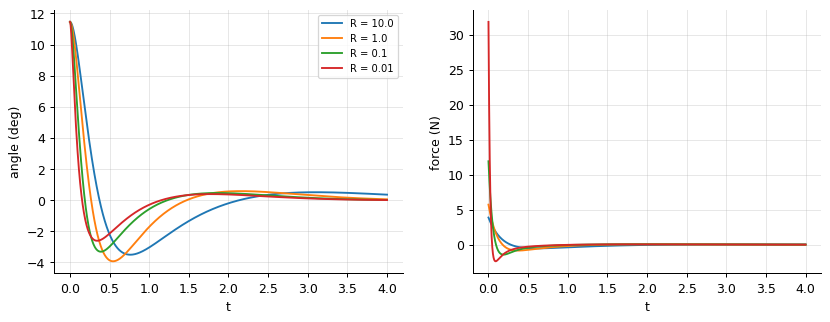

     R  peak force (N)  angle settled (s)  cart excursion (cm)  fastest pole |Re|
10.000           3.879              0.368               35.775              5.777
 1.000           5.722              0.264               23.255              7.029
 0.100          11.922              0.188               16.519             12.298
 0.010          31.852              0.152               13.790             48.612

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rows = []
for rho in (10.0, 1.0, 0.1, 0.01):
    rr = sp.lqr(A, B, Q, np.array([[rho]]))
    Acl = sy.ss(A - B @ rr["K"], B, C, np.zeros((2, 1)))
    t, y, x = rs.initial(Acl, x0, 4.0)
    u = -(x @ rr["K"].T)[:, 0]
    axes[0].plot(t, np.degrees(x[:, 2]), label=f"R = {rho}"); axes[1].plot(t, u)
    rows.append((rho, np.max(np.abs(u)), t[np.argmax(np.abs(x[:, 2]) < 0.01 * 0.2)] if np.any(np.abs(x[:, 2]) < 0.002) else np.nan, np.max(np.abs(x[:, 0])) * 100, np.max(np.abs(rr["closed_loop_poles"].real))))
axes[0].set_ylabel("angle (deg)"); axes[0].legend(fontsize=8); axes[1].set_ylabel("force (N)"); axes[0].set_xlabel("t"); axes[1].set_xlabel("t"); plt.show()
print(pd.DataFrame(rows, columns=["R", "peak force (N)", "angle settled (s)", "cart excursion (cm)", "fastest pole |Re|"]).to_string(index=False, float_format="%.3f"))

Lowering the control weight R buys speed with force: the pendulum settles faster, the peak force and the
fastest pole grow. The weights are the design knobs, and their effect is monotone and predictable - which is
why LQR is the method of choice when the actuator's limits are known: choose R so that the peak force fits
them. Bryson's rule (weight each variable by the inverse square of its allowed excursion) is the usual
starting point.

## Integral action

closed-loop poles with integral action: [-20.52 +0.j     -8.334-5.293j  -8.334+5.293j]


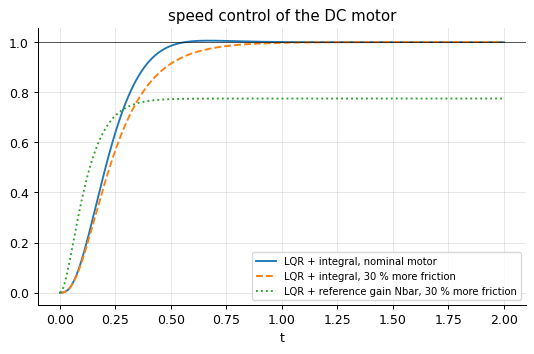

final values: 1.0000, 1.0000, 0.7748


In [4]:
mot = models.dc_motor()["system"]
li = sp.lqr_integral(mot.A, mot.B, mot.C, np.diag([1.0, 10.0]), np.array([[0.01]]), qi=1e4)
print("closed-loop poles with integral action:", np.round(np.sort_complex(li["closed_loop_poles"]), 3))
Aa, Ba = li["Aa"], li["Ba"]
Ka = np.hstack([li["K"], li["Ki"]])
# closed loop of the augmented system: xa' = (Aa - Ba Ka) xa + [0; 1] r, y = C x
Acl = Aa - Ba @ Ka
Bcl = np.array([[0.0], [0.0], [1.0]])
Ccl = np.hstack([mot.C, np.zeros((1, 1))])
cl = sy.ss(Acl, Bcl, Ccl, 0.0)
t, y = rs.step(cl, 2.0)
# a model error: the real motor has 30 % more friction
mot_real = models.dc_motor(b=0.13)["system"]
Acl_r = np.block([[mot_real.A - mot_real.B @ li["K"], -mot_real.B @ li["Ki"]], [-mot_real.C, np.zeros((1, 1))]])
t2, y2 = rs.step(sy.ss(Acl_r, Bcl, np.hstack([mot_real.C, np.zeros((1, 1))]), 0.0), 2.0)
Km = sp.lqr(mot.A, mot.B, np.diag([1.0, 10.0]), np.array([[0.01]]))["K"]
Nbar = sp.reference_gain(mot.A, mot.B, mot.C, Km)
t3, y3 = rs.step(sy.ss(mot_real.A - mot_real.B @ Km, mot_real.B * Nbar, mot_real.C, 0.0), 2.0)
plt.plot(t, y, label="LQR + integral, nominal motor"); plt.plot(t2, y2, "--", label="LQR + integral, 30 % more friction"); plt.plot(t3, y3, ":", label="LQR + reference gain Nbar, 30 % more friction"); plt.axhline(1, color="k", lw=0.5); plt.legend(fontsize=8); plt.xlabel("t"); plt.title("speed control of the DC motor"); plt.show()
print(f"final values: {y[-1]:.4f}, {y2[-1]:.4f}, {y3[-1]:.4f}")

Augmenting the state with the integral of the tracking error and weighting it turns LQR into a controller with
integral action: the speed settles at the reference even when the motor's friction is 30 % off the model,
where the feedforward gain N̄ leaves a 23 % offset. The integral weight q_i sets how fast the offset is
removed; the trade-off with overshoot is the same as for any PI loop.

## Guaranteed margins

In [5]:
for name, (A_, B_, Q_, R_) in (("DC motor", (mot.A, mot.B, np.diag([1.0, 10.0]), np.array([[0.01]]))), ("cart-pendulum", (A, B, Q, R))):
    m = sp.lqr_margins(A_, B_, Q_, R_)
    gms = [float(round(g_, 3)) for g_ in m["gain_margins"]] or ["none (never crosses -180)"]
    print(f"{name:<14}: loop K (sI - A)^-1 B at the plant input: gain margins at the phase crossovers {gms} (guaranteed: can be reduced to 1/2 and raised without limit), phase margin {m['phase_margin']:.1f} deg (>= 60 guaranteed)")
L_lqr = sy.ss(A, B, K, np.zeros((1, 1))).to_tf()
w = np.logspace(-1, 2, 2000)
_, Lj = fr.nyquist(L_lqr, w)
print(f"return difference |1 + L| >= 1 at every frequency: minimum {np.min(np.abs(1 + Lj)):.4f} (Kalman's inequality)")

DC motor      : loop K (sI - A)^-1 B at the plant input: gain margins at the phase crossovers ['none (never crosses -180)'] (guaranteed: can be reduced to 1/2 and raised without limit), phase margin 95.3 deg (>= 60 guaranteed)
cart-pendulum : loop K (sI - A)^-1 B at the plant input: gain margins at the phase crossovers [0.212] (guaranteed: can be reduced to 1/2 and raised without limit), phase margin 70.9 deg (>= 60 guaranteed)
return difference |1 + L| >= 1 at every frequency: minimum 1.0119 (Kalman's inequality)


Kalman's return-difference inequality |1 + L(jω)| ≥ 1 says the LQR loop never comes closer than 1 to −1: a
gain margin from 1/2 to infinity and a phase margin of at least 60°, for any plant and any weights, at the
plant input. The motor's loop never reaches −180° (no gain crossover of the phase, hence no finite gain
margin); the pendulum's, being unstable in open loop, has a *downward* gain margin - the loop goes unstable if
the gain falls to 0.21, below the guaranteed 1/2 - and none upward. These are the margins that LQG loses when an observer is inserted (notebook 11) and that loop
transfer recovery tries to regain. They hold for the state-feedback loop; what the designer still has to
check is the actuator and the model's validity at the resulting bandwidth.

## Inside the algorithm: Newton-Kleinman iteration for the Riccati equation

In [6]:
S_ = B @ np.linalg.solve(R, B.T)
K0 = sp.place(A, B, [-1, -2, -3, -4])              # any stabilising gain to start
Pk = la.lyapunov((A - B @ K0).T, Q + K0.T @ R @ K0)
for it in range(6):
    Kk = np.linalg.solve(R, B.T @ Pk)
    Pk = la.lyapunov((A - B @ Kk).T, Q + Kk.T @ R @ Kk)
    print(f"iteration {it + 1}: |P_k - P| = {np.max(np.abs(Pk - P)):.2e}")

iteration 1: |P_k - P| = 3.33e+01
iteration 2: |P_k - P| = 1.23e+01
iteration 3: |P_k - P| = 3.23e+00
iteration 4: |P_k - P| = 3.88e-01
iteration 5: |P_k - P| = 9.33e-03
iteration 6: |P_k - P| = 9.98e-06


## Exercises
1. Apply Bryson's rule to the cart-pendulum: allowed excursions 0.1 m, 0.5 m/s, 0.05 rad, 0.5 rad/s and 5 N. Simulate the recovery from 10 degrees and check whether the force stays within 5 N; adjust R until it does.
2. For the DC motor speed loop compare LQR with integral action (qi = 10, 100, 1000) against a PI controller tuned for the same settling time: overshoot, control effort, and response to a load torque step (an input disturbance).
3. **Implement it yourself:** compute the LQR cost J = int (x'Qx + u'Ru) dt by simulating the closed loop from x0 with `response.initial` and integrating numerically; compare with x0' P x0 and show that any other stabilising gain (e.g. from pole placement) gives a larger cost.